# Monotonicity constraints with `bmono`: five cases

`bmono` fits a P-spline whose coefficients are forced to run in one direction, so
the fitted curve can bend and flatten but never reverse. The direction is
supplied by the analyst from mechanism — a larger apartment cannot rent for
less, a larger waist cannot mean less body fat — and not estimated from the
data.

Each section compares a free (unconstrained) fit with a constrained fit to
measure the consequences of supplying that direction. In sections 1 to 4, the comparison does not rest on predictive accuracy inside the range of the data. In sections 1 and 3, the in-range cross-validated fits differ by less than half a percent. The differences appear elsewhere — past the last
observation, across resamples, in the sign of a reported effect, and in which
variables enter the model.

The fifth section imposes a direction on a relation that does not have one, and
there the cross-validated cost rises by a multiple rather than a fraction of a
percent. That contrast is what makes the cost worth computing, and the closing
section uses it.

The page consists of five independent experiments. Each states the role of the
constraint, fits a free and a constrained alternative, and compares them.


:::{admonition} What this study estimates
:class: dropdown

| | |
|---|---|
| **Target** | five situations in which a monotonicity constraint is or is not the right instrument |
| **Observed response** | varies by situation: `DEXfat` in kg, `accel` in g, `rentsqm` in euros per m² |
| **Estimand** | the constrained partial effect, against its unconstrained counterpart |
| **Units** | as above, per situation |
| **Sampling unit** | one woman, one crash instant, or one apartment, depending on the situation |
| **Dependence** | independent for body fat, serially dependent for the crash series, district-clustered for the rents |
| **Split / resampling unit** | matches the sampling unit in each situation |
| **Tuning** | fixed `mstop` within each comparison so the constraint is the only difference |
| **Uncertainty** | bootstrap refits of the constrained and unconstrained fits |
| **Claim type** | methodological. The constraint comes from mechanism supplied by the analyst, and is not estimated from the data |
:::


In [1]:
import warnings

import collections
import numpy as np
import polars as pl
import altair as alt

import mboostrs as mb

warnings.filterwarnings("ignore")

FREE = "#e15759"
MONO = "#4e79a7"
LINE = "#8a8a8a"

## 1. Extrapolation past the last observation

A fitted curve returns a value for any input, including inputs larger than
anything in the training data. Outside the training range, predictions
depend on the learner. A P-spline (`bbs`) is a penalized piecewise cubic
polynomial whose pieces join at points called knots; the outermost knots, the
boundary knots, sit at the smallest and largest training value. Beyond its
boundary knot a P-spline continues at the slope it had there, and that slope is
estimated from the sparsest part of the sample, so its sign is not reliable.
`bmono` uses the same basis with its coefficients constrained to be monotone.

The Munich rent survey records `rentsqm`, rent per square metre, which falls
steeply with floor area and then flattens — monotone, and distinctly not a
straight line. Apartments of 100 m² or less are the training set; the larger
ones are held out, so every prediction on them is an extrapolation.


In [2]:
survey = mb.datasets.munich_rent(output="records")
columns = {k: np.asarray(v).astype(float) for k, v in survey.items() if k != "district"}

in_range = columns["area"] <= 100
train = {k: v[in_range] for k, v in columns.items()}
beyond = {k: v[~in_range] for k, v in columns.items()}

covariates = ("yearc", "location", "bath", "kitchen", "cheating")
rest = ("bbs(yearc, df=4) + bols(location) + bols(bath) + bols(kitchen) "
        "+ bols(cheating)")

area_terms = {
    "bbs (free)": "bbs(area, df=4)",
    "bols (straight line)": "bols(area)",
    "bmono (decreasing)": "bmono(area, df=4, constraint='decreasing', type='quad.prog')",
}

print(f"training apartments {len(train['rentsqm'])}   held out {len(beyond['rentsqm'])}")

n_survey = len(columns["rentsqm"])
n_train = len(train["rentsqm"])
n_beyond = len(beyond["rentsqm"])


training apartments 2826   held out 256


That leaves {eval}`n_train` apartments to train on and {eval}`n_beyond`
between 101 and 160 m² held out, of {eval}`n_survey` surveyed.

Three learners for floor area are compared on two measures. The first is
five-fold cross-validation inside the training range, the usual basis for
choosing between learners. The second is mean absolute error on the held-out
large apartments, which the cross-validation never touches.

In [3]:
def at_area(areas, source=train):
    grid = np.asarray(areas, dtype=float)
    return {"area": grid,
            **{c: np.full(len(grid), float(np.median(source[c]))) for c in covariates}}

query = at_area([60, 100, 130, 160])

rng = np.random.default_rng(0)

fold = rng.permutation(len(train["rentsqm"])) % 5

rows = []


In [4]:
for label, term in area_terms.items():
    spec = f"rentsqm ~ {term} + {rest}"
# Reuse the declared folds so comparisons differ by model, not by split.
    inside = []
    for k in range(5):
        fitted = mb.gamboost(spec,
                             data={c: v[fold != k] for c, v in train.items()},
                             family=mb.Gaussian(),
                             control=mb.boost_control(500, 0.1))
        held = {c: v[fold == k] for c, v in train.items() if c != "rentsqm"}
        inside.append(np.mean(np.abs(train["rentsqm"][fold == k]
                                     - np.asarray(fitted.predict(newdata=held)).ravel())))

    model = mb.gamboost(spec, data=train, family=mb.Gaussian(),
                        control=mb.boost_control(500, 0.1))
    outside = np.asarray(model.predict(
        newdata={c: v for c, v in beyond.items() if c != "rentsqm"})).ravel()

    rows.append({
        "area learner": label,
        "in-range CV MAE": round(float(np.mean(inside)), 3),
        "beyond MAE": round(float(np.mean(np.abs(beyond["rentsqm"] - outside))), 3),
        "at 100 m2": round(float(np.asarray(model.predict(newdata=query)).ravel()[1]), 2),
        "at 160 m2": round(float(np.asarray(model.predict(newdata=query)).ravel()[3]), 2),
    })

observed = columns["rentsqm"][(columns["area"] >= 140) & (columns["area"] <= 160)]

print(f"observed mean rent per m2, 140-160 m2: {observed.mean():.2f} "
      f"(n = {len(observed)})")


observed mean rent per m2, 140-160 m2: 5.92 (n = 29)


In [5]:
display(pl.DataFrame(rows))

# Quantities the prose quotes, named here so a rerun moves the sentences too.

by_learner = {r["area learner"]: r for r in rows}

free_name, line_name, mono_name = list(area_terms)

in_range_all = ", ".join(f"{by_learner[n]['in-range CV MAE']:.3f}" for n in area_terms)

free_beyond = f"{by_learner[free_name]['beyond MAE']:.3f}"

line_beyond = f"{by_learner[line_name]['beyond MAE']:.3f}"

mono_beyond = f"{by_learner[mono_name]['beyond MAE']:.3f}"

free_at_100 = f"{by_learner[free_name]['at 100 m2']:.2f}"

free_at_160 = f"{by_learner[free_name]['at 160 m2']:.2f}"

line_at_160 = f"{by_learner[line_name]['at 160 m2']:.2f}"

observed_mean = f"{observed.mean():.2f}"

free_in_range = f"{by_learner[free_name]['in-range CV MAE']:.3f}"

mono_in_range = f"{by_learner[mono_name]['in-range CV MAE']:.3f}"

mono_ratio = (by_learner[mono_name]["in-range CV MAE"]
              / by_learner[free_name]["in-range CV MAE"])

mono_cost_pct = f"{100 * (mono_ratio - 1):.2f}%"


area learner,in-range CV MAE,beyond MAE,at 100 m2,at 160 m2
str,f64,f64,f64,f64
"""bbs (free)""",1.517,1.631,5.82,6.64
"""bols (straight line)""",1.545,1.727,4.99,2.34
"""bmono (decreasing)""",1.518,1.503,5.65,5.41


The three in-range figures are {eval}`in_range_all`. On the evidence
cross-validation supplies, the three learners are interchangeable.

Beyond the training range they are not. The free spline scores
{eval}`free_beyond`, the straight line {eval}`line_beyond`, the monotone spline
{eval}`mono_beyond`. The free spline's error comes from a reversal: it predicts
{eval}`free_at_100` per square metre at 100 m² and {eval}`free_at_160` at
160 m², so it has larger apartments costing more per square metre, which is the
opposite of the relation it was fitted on. The straight line keeps the direction
and loses the shape, running down to {eval}`line_at_160` where the surveyed
apartments average {eval}`observed_mean`. The monotone spline is the only one of
the three that keeps both.

The constraint costs almost nothing in the training range,
{eval}`mono_in_range` against {eval}`free_in_range`, because it barely binds
there: the free fit already runs downhill, so forbidding an upturn changes
little. It binds past the boundary knot, and cross-validation draws its folds
from the same range as the training data, so it has no observations in the
region where the constraint acts.


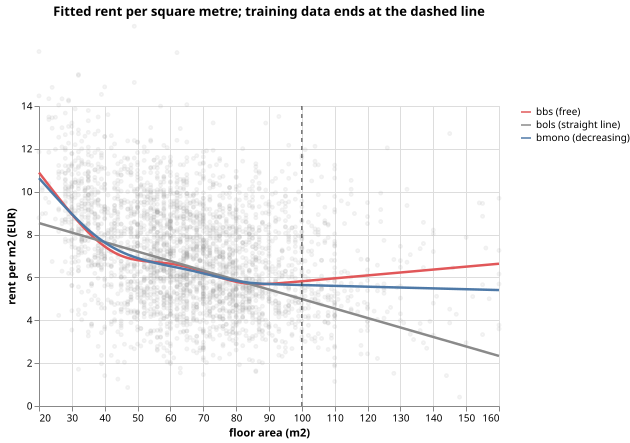

In [6]:
grid = np.linspace(20, 160, 141)
curves = []
for label, term in area_terms.items():
    model = mb.gamboost(f"rentsqm ~ {term} + {rest}", data=train,
                        family=mb.Gaussian(), control=mb.boost_control(500, 0.1))
    curves.append(pl.DataFrame({
        "area": grid,
        "rentsqm": np.asarray(model.predict(newdata=at_area(grid))).ravel(),
        "learner": [label] * len(grid),
    }))
curves = pl.concat(curves)
# Plot the quantities interpreted in the following paragraph.
points = alt.Chart(pl.DataFrame({"area": columns["area"], "rentsqm": columns["rentsqm"]})
                   ).mark_point(size=8, opacity=0.15, color="#999999").encode(
    x=alt.X("area:Q", title="floor area (m2)", scale=alt.Scale(domain=[20, 160])),
    y=alt.Y("rentsqm:Q", title="rent per m2 (EUR)", scale=alt.Scale(domain=[0, 14])),
)
lines = alt.Chart(curves).mark_line(strokeWidth=2.5).encode(
    x="area:Q", y="rentsqm:Q",
    color=alt.Color("learner:N", title=None,
                    scale=alt.Scale(domain=list(area_terms),
                                    range=[FREE, LINE, MONO])),
)
edge = alt.Chart(pl.DataFrame({"area": [100.0]})).mark_rule(
    strokeDash=[4, 4], color="#333333").encode(x="area:Q")
(points + lines + edge).properties(
    width=460, height=300,
    title="Fitted rent per square metre; training data ends at the dashed line")


## 2. Shape variation across samples

A free fit that is monotone on one sample describes that sample; another small
sample from the same population may produce a different shape.

`bodyfat` records body fat in kg, measured by dual-energy X-ray absorptiometry
(DEXA), for 71 women, alongside several anthropometric predictors. Waist circumference raising body fat is not in doubt, and the fit on
the full sample respects that.


In [7]:
body = {k: np.asarray(v).astype(float)
        for k, v in mb.datasets.bodyfat(output="records").items()}
# Evaluate the fitted model on the study's declared rows or prediction grid.
fat_spec = ("DEXfat ~ {waist} + bbs(hipcirc, df=4) + bbs(age, df=4) "
            "+ bbs(kneebreadth, df=4)")
waist_grid = np.linspace(np.percentile(body["waistcirc"], 2),
                         np.percentile(body["waistcirc"], 98), 61)


def waist_effect(sample, waist_term="bbs(waistcirc, df=4)"):
    model = mb.gamboost(fat_spec.format(waist=waist_term), data=sample,
                        family=mb.Gaussian(), control=mb.boost_control(300, 0.1))
    newdata = {c: np.full(len(waist_grid), float(np.mean(v)))
               for c, v in body.items() if c != "DEXfat"}
    newdata["waistcirc"] = waist_grid
    fitted = np.asarray(model.predict(newdata=newdata)).ravel()
    return fitted - fitted.mean()


full = waist_effect(body)
n_subjects = len(body["DEXfat"])
n_resamples = 40
waist_span = f"{full.max() - full.min():.2f}"
print(f"n = {n_subjects}")
print(f"fitted waist effect, end to end   {full.max() - full.min():.2f} kg")
n_grid_intervals = len(full) - 1
print(f"grid intervals on which it falls  "
      f"{int((np.diff(full) < -1e-9).sum())} of {n_grid_intervals}")


n = 71
fitted waist effect, end to end   13.86 kg
grid intervals on which it falls  0 of 60


The fitted waist effect rises across its whole range on all
{eval}`n_subjects` subjects, by {eval}`waist_span` kg from end to end, and falls
on none of the {eval}`n_grid_intervals` grid intervals.

Refitting on {eval}`n_resamples` bootstrap resamples asks how much of that shape
belongs to the model and how much to the sample. Each resample draws
{eval}`n_subjects` subjects with replacement and repeats the fit.


In [8]:
resample_rng = np.random.default_rng(5)
paths, falling, drops = [], 0, []
for b in range(n_resamples):
    idx = resample_rng.integers(0, len(body["DEXfat"]), len(body["DEXfat"]))
    curve = waist_effect({k: v[idx] for k, v in body.items()})
    step = np.diff(curve)
    if (step < -1e-9).any():
        falling += 1
        drops.append(float(-step[step < -1e-9].sum()))
    paths.append(pl.DataFrame({
        "waistcirc": waist_grid, "effect": curve,
        "draw": [b] * len(waist_grid),
        "shape": ["falls somewhere" if (step < -1e-9).any() else "rises throughout"]
                 * len(waist_grid),
    }))

drop_median = f"{np.median(drops):.2f}"
drop_max = f"{max(drops):.2f}"
print(f"resamples whose fitted waist effect falls somewhere: "
      f"{falling} of {n_resamples}")
print(f"size of the fall: median {drop_median} kg, largest {drop_max} kg")

resamples whose fitted waist effect falls somewhere: 6 of 40
size of the fall: median 0.73 kg, largest 1.72 kg


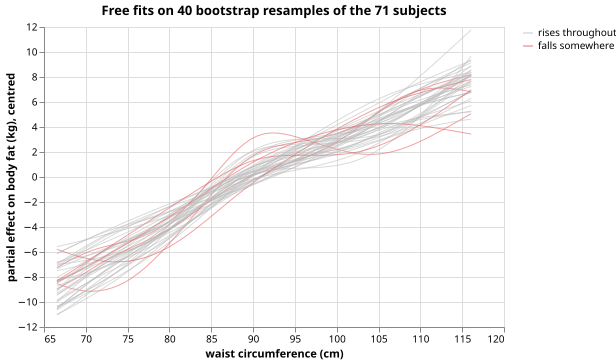

In [9]:
spaghetti = alt.Chart(pl.concat(paths)).mark_line(strokeWidth=1, opacity=0.55).encode(
    x=alt.X("waistcirc:Q", title="waist circumference (cm)"),
    y=alt.Y("effect:Q", title="partial effect on body fat (kg), centred"),
    detail="draw:N",
    color=alt.Color("shape:N", title=None,
                    scale=alt.Scale(domain=["rises throughout", "falls somewhere"],
                                    range=["#bbbbbb", FREE])),
)
spaghetti.properties(width=460, height=300,
                     title=f"Free fits on {n_resamples} bootstrap resamples of the {n_subjects} subjects")

{eval}`falling` of the {eval}`n_resamples` resamples produce a curve that falls
somewhere, by a median of {eval}`drop_median` kg and at most {eval}`drop_max` kg.
Against a {eval}`waist_span` kg effect those reversals are small. They are still
reversals: on that sample, the fitted model answers "less body fat" to a larger
waist over some stretch of the range.

Whether that matters depends on what the curve is for. As a description of the
{eval}`n_subjects` subjects it does not. As a function that will be evaluated at
a new subject's waist measurement and reported, it does, because nothing in the
fitting procedure prevents the next sample from being one of the
{eval}`falling`. `bmono` moves monotonicity from a property of the sample to a
property of the model.


## 3. Confounding that reverses the sign

The data below are simulated so the causal effect is known. Four hundred
patients receive a dose between 0 and 10. Severity of illness raises the dose a
patient is given and lowers the response, and it is not recorded:

$$
\begin{aligned}
\text{severity} &\sim N(0, 1) \\
\text{dose} &= \operatorname{clip}(5 + 1.5\,\text{severity} + \varepsilon_d,\ 0,\ 10) \\
y &= 0.8\,\text{dose} - 2.5\,\text{severity} + \varepsilon_y
\end{aligned}
$$

The drug raises the response by 0.8 per unit at every dose. In the sample, dose
and response correlate negatively, because the patients on high doses were the
sicker ones to begin with. This is confounding by indication
{cite}`walker1996confounding`.

In [10]:
conf_rng = np.random.default_rng(0)
n_patients = 400

severity = conf_rng.normal(0, 1, n_patients)
dose = np.clip(5 + 1.5 * severity + conf_rng.normal(0, 1.2, n_patients), 0, 10)
trial = {"dose": dose,
         "y": 0.8 * dose - 2.5 * severity + conf_rng.normal(0, 1.0, n_patients)}

dose_grid = np.linspace(1, 9, 41)
true_effect = 0.8 * dose_grid
true_effect = true_effect - true_effect.mean()

print(f"corr(dose, y) in the sample   {np.corrcoef(trial['dose'], trial['y'])[0, 1]:+.3f}")
print(f"true effect of the drug       +0.80 per unit of dose, at every dose")

corr(dose, y) in the sample   -0.208
true effect of the drug       +0.80 per unit of dose, at every dose


In [11]:
dose_terms = {
    "free": "bbs(dose, df=4)",
    "increasing": "bmono(dose, df=4, constraint='increasing', type='quad.prog')",
}
# Evaluate the fitted model on the study's declared rows or prediction grid.
conf_rows, conf_curves = [], []
for label, term in dose_terms.items():
    model = mb.gamboost(f"y ~ {term}", data=trial, family=mb.Gaussian(),
                        control=mb.boost_control(400, 0.1))
    curve = np.asarray(model.predict(newdata={"dose": dose_grid})).ravel()
    curve = curve - curve.mean()
    conf_rows.append({
        "dose learner": label,
        "fitted change, dose 1 to 9": round(float(curve[-1] - curve[0]), 2),
        "mean distance from the truth": round(float(np.abs(curve - true_effect).mean()), 2),
    })
    conf_curves.append(pl.DataFrame({"dose": dose_grid, "effect": curve,
                                     "curve": [label] * len(dose_grid)}))

conf_curves.append(pl.DataFrame({"dose": dose_grid, "effect": true_effect,
                                 "curve": ["true effect"] * len(dose_grid)}))
print(f"true change from dose 1 to 9: {true_effect[-1] - true_effect[0]:+.2f}")
display(pl.DataFrame(conf_rows))

by_dose = {r["dose learner"]: r for r in conf_rows}
free_change = f"{by_dose['free']['fitted change, dose 1 to 9']:.2f}"
mono_change = f"{by_dose['increasing']['fitted change, dose 1 to 9']:.2f}"
true_change = f"{true_effect[-1] - true_effect[0]:.2f}"
free_distance = f"{by_dose['free']['mean distance from the truth']:.2f}"
mono_distance = f"{by_dose['increasing']['mean distance from the truth']:.2f}"


true change from dose 1 to 9: +6.40


dose learner,"fitted change, dose 1 to 9",mean distance from the truth
str,f64,f64
"""free""",-1.68,2.01
"""increasing""",0.0,1.64


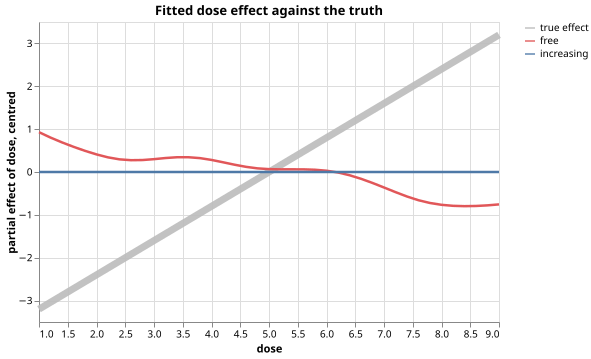

In [12]:
palette = alt.Color("curve:N", title=None,
                    scale=alt.Scale(domain=["true effect", "free", "increasing"],
                                    range=["#bbbbbb", FREE, MONO]))
frame = pl.concat(conf_curves)
truth_band = alt.Chart(frame).transform_filter(
    alt.datum.curve == "true effect").mark_line(strokeWidth=7, opacity=0.9).encode(
    x=alt.X("dose:Q", title="dose"),
    y=alt.Y("effect:Q", title="partial effect of dose, centred"), color=palette)
fits = alt.Chart(frame).transform_filter(
    alt.datum.curve != "true effect").mark_line(strokeWidth=2.5).encode(
    x="dose:Q", y="effect:Q", color=palette)
(truth_band + fits).properties(
    width=460, height=300, title="Fitted dose effect against the truth")

The free fit reports a change of {eval}`free_change` across the dose range,
where the truth rises by {eval}`true_change`. Read as a dose–response it
says the drug harms patients.

The constrained fit reports a change of {eval}`mono_change`. It does not recover
the effect — the information needed to separate dose from severity is not in the
data, and no constraint can supply it. The constraint excludes the negative
slope. With no evidence for an increasing slope, the fitted curve is nearly
flat.

Both fits miss the causal effect because severity is unavailable. The
constraint prevents a negative fitted direction but leaves a nearly flat
curve, which still disagrees with the known increasing effect. The mean
distance from the truth falls from {eval}`free_distance` to
{eval}`mono_distance`; this measures the partial improvement rather than causal
identification.


In [13]:
conf_fold = np.random.default_rng(0).permutation(n_patients) % 5
conf_cv = {}
for label, term in dose_terms.items():
    errors = []
    for k in range(5):
        model = mb.gamboost(f"y ~ {term}",
                            data={c: v[conf_fold != k] for c, v in trial.items()},
                            family=mb.Gaussian(), control=mb.boost_control(400, 0.1))
        predicted = np.asarray(model.predict(
            newdata={"dose": trial["dose"][conf_fold == k]})).ravel()
        errors.append(np.mean((trial["y"][conf_fold == k] - predicted) ** 2))
    conf_cv[label] = float(np.mean(errors))
    print(f"5-fold CV MSE, dose effect {label:11s} {conf_cv[label]:.4f}")
conf_free = f"{conf_cv['free']:.4f}"
conf_mono = f"{conf_cv['increasing']:.4f}"
conf_cost_pct = f"{100 * (conf_cv['increasing'] / conf_cv['free'] - 1):.1f}%"


5-fold CV MSE, dose effect free        3.1758


5-fold CV MSE, dose effect increasing  3.1900


Cross-validation does not separate the two fits: {eval}`conf_free` free against
{eval}`conf_mono` constrained, a difference of {eval}`conf_cost_pct`. Both
describe these patients about equally well. The free fit reports that the
drug harms patients (a change of {eval}`free_change`), and the constrained fit
reports no effect (a change of {eval}`mono_change`). Prediction on data drawn the same way is not sensitive to the question
the fit was made to answer.


## 4. Effect on variable selection

A shape constraint applies to one learner. It can change which of the other
learners are selected, because boosting picks the learner that best fits the
current residual at every step, and forbidding a shape changes what the
residuals look like.

The data are simulated. Patients come from two sites. Site 1 treats sicker
patients: it gives higher doses, and its patients start from a baseline 3.5
lower. Doses cluster around 2 at site 0 and around 6 at site 1, so the two sites
occupy separate parts of the dose range. Within each site the response rises by
1.0 per unit of dose. The candidate set is dose, site, and a noise variable
carrying no signal.

In [14]:
def two_sites(rng, rows=300):
    dose = np.where(rng.random(rows) < 0.5,
                    rng.normal(2.0, 0.7, rows), rng.normal(6.0, 0.7, rows))
    site = (dose > 4.0).astype(float)
    y = (rng.normal(0.0, 1.5, rows) + 4.0 - 3.5 * site + 1.0 * dose
         + rng.normal(0.0, 0.6, rows))
    return {"dose": dose, "site": site, "S": rng.normal(0, 1, rows), "y": y}
# Fix the random draw so the resampling result is reproducible.
site_grid = np.linspace(1, 7, 61)

at_five = int(np.abs(site_grid - 5.0).argmin())

picked = {label: 0 for label in dose_terms}

effect_at_five = {label: [] for label in dose_terms}

n_replicates = 20

for replicate in range(n_replicates):
    sample = two_sites(np.random.default_rng(100 + replicate))
    for label, term in dose_terms.items():
        model = mb.gamboost(f"y ~ {term} + bols(site) + bols(S)",
                            data=sample, family=mb.Gaussian(),
                            control=mb.boost_control(300, 0.1))
        if collections.Counter(list(model.selected)).get("site", 0) > 0:
            picked[label] += 1
        newdata = {"dose": site_grid,
                   "site": np.full(61, float(sample["site"].mean())),
                   "S": np.full(61, float(sample["S"].mean()))}
        curve = np.asarray(model.predict(newdata=newdata)).ravel()
        effect_at_five[label].append(float((curve - curve.mean())[at_five]))


In [15]:
display(pl.DataFrame([
    {"dose learner": label,
     "selects site": f"{picked[label]} of {n_replicates}",
     "mean fitted effect at dose 5": round(float(np.mean(effect_at_five[label])), 2)}
    for label in dose_terms
]))

print("true within-site effect at dose 5: +1.00")

free_picks = picked["free"]

mono_picks = picked["increasing"]

free_at_five = f"{np.mean(effect_at_five['free']):+.2f}"

mono_at_five = f"{np.mean(effect_at_five['increasing']):+.2f}"


dose learner,selects site,mean fitted effect at dose 5
str,str,f64
"""free""","""6 of 20""",-0.61
"""increasing""","""20 of 20""",0.03


true within-site effect at dose 5: +1.00


The free fit selects site in {eval}`free_picks` of the {eval}`n_replicates`
samples; the constrained fit selects it in all {eval}`mono_picks`.

The 3.5-unit offset between the sites is the source of the difference. A free
spline can carry the offset by bending the dose curve downward across the gap
between the two dose clusters, and in the samples where it does, the site
variable has little left to explain and is not picked. A monotone spline cannot take that bend, so the offset has to be carried
by a variable that separates the sites, and only site does.

The estimate follows the selection. At a dose of 5, where the truth is +1.00,
the free fits average {eval}`free_at_five` and the constrained fits
{eval}`mono_at_five`. The free fits report the wrong sign in the middle of the
dose range because that is where the bend sits.

This depends on the sites occupying separate parts of the dose range. If both
sites drew doses from the same range, no dose curve could separate them, the
offset would fall on the site variable either way, and the constraint would be
expected to leave the selection unchanged. That case is not simulated here.


## 5. A constraint in the wrong direction

Sections 1 to 4 assume the direction is known. This one imposes a
direction on a relation that does not have one.

`motorcycle` holds measurements of head acceleration from a simulated
motorcycle crash, recorded against time in milliseconds after impact. The head
is barely disturbed for the first 10 ms, accelerates sharply downward to a
trough near 20 ms, rebounds above zero by 30 ms, and settles. The relation is
not monotone and no mechanism suggests it should be.


In [16]:
crash = {k: np.asarray(v).astype(float)
         for k, v in mb.datasets.motorcycle(output="records").items()}

time_grid = np.linspace(crash["times"].min(), crash["times"].max(), 81)

crash_terms = {
    "free": "bbs(times, df=4)",
    "decreasing": "bmono(times, df=4, constraint='decreasing', type='quad.prog')",
    "increasing": "bmono(times, df=4, constraint='increasing', type='quad.prog')",
}

crash_rng = np.random.default_rng(0)

crash_fold = crash_rng.permutation(len(crash["times"])) % 5

crash_rows, crash_curves = [], []


In [17]:
for label, term in crash_terms.items():
    errors = []
    for k in range(5):
        model = mb.gamboost(f"accel ~ {term}",
                            data={c: v[crash_fold != k] for c, v in crash.items()},
                            family=mb.Gaussian(), control=mb.boost_control(500, 0.1))
        predicted = np.asarray(model.predict(
            newdata={"times": crash["times"][crash_fold == k]})).ravel()
        errors.append(np.mean((crash["accel"][crash_fold == k] - predicted) ** 2))
# Reuse the declared folds so comparisons differ by model, not by split.
    model = mb.gamboost(f"accel ~ {term}", data=crash, family=mb.Gaussian(),
                        control=mb.boost_control(500, 0.1))
    curve = np.asarray(model.predict(newdata={"times": time_grid})).ravel()
    crash_rows.append({
        "time learner": label,
        "5-fold CV MSE": round(float(np.mean(errors)), 1),
        "lowest fitted value": round(float(curve.min()), 1),
        "highest fitted value": round(float(curve.max()), 1),
    })
    crash_curves.append(pl.DataFrame({"times": time_grid, "accel": curve,
                                      "learner": [label] * len(time_grid)}))

display(pl.DataFrame(crash_rows))

by_time = {r["time learner"]: r for r in crash_rows}

def span(label):
    row = by_time[label]
    return f"{row['lowest fitted value']:.1f} to {row['highest fitted value']:.1f}"

n_crash = len(crash["times"])


time learner,5-fold CV MSE,lowest fitted value,highest fitted value
str,f64,f64,f64
"""free""",627.7,-98.8,31.8
"""decreasing""",2265.7,-30.4,11.9
"""increasing""",1722.6,-50.1,19.4


In [18]:
free_span, down_span, up_span = (span(k) for k in crash_terms)

free_mse = f"{by_time['free']['5-fold CV MSE']:.1f}"

down_mse = f"{by_time['decreasing']['5-fold CV MSE']:.1f}"

up_mse = f"{by_time['increasing']['5-fold CV MSE']:.1f}"

down_ratio = f"{by_time['decreasing']['5-fold CV MSE'] / by_time['free']['5-fold CV MSE']:.1f}"

up_ratio = f"{by_time['increasing']['5-fold CV MSE'] / by_time['free']['5-fold CV MSE']:.1f}"

down_ratio_pct = (by_time["decreasing"]["5-fold CV MSE"]
                  / by_time["free"]["5-fold CV MSE"])

down_cost_pct = f"{100 * (down_ratio_pct - 1):.0f}%"


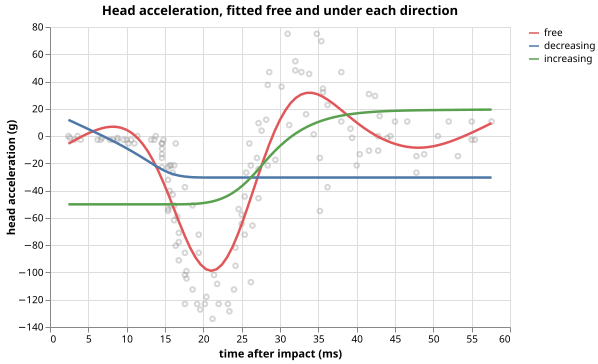

In [19]:
observed = alt.Chart(pl.DataFrame({"times": crash["times"], "accel": crash["accel"]})
                     ).mark_point(size=22, opacity=0.4, color="#999999").encode(
    x=alt.X("times:Q", title="time after impact (ms)"),
    y=alt.Y("accel:Q", title="head acceleration (g)"))
fitted = alt.Chart(pl.concat(crash_curves)).mark_line(strokeWidth=2.5).encode(
    x="times:Q", y="accel:Q",
    color=alt.Color("learner:N", title=None,
                    scale=alt.Scale(domain=list(crash_terms),
                                    range=[FREE, MONO, "#59a14f"])))
(observed + fitted).properties(
    width=460, height=300,
    title="Head acceleration, fitted free and under each direction")

The free fit tracks the trough and the rebound, spanning {eval}`free_span` g
over the {eval}`n_crash` measurements. Each constrained fit collapses to a
fraction of that range — {eval}`down_span` g when forced to decrease,
{eval}`up_span` g when forced to increase — because a curve that runs in one
direction cannot represent a trough. Neither constrained fit shows any sign of
the trough it removed.

Cross-validation charges {eval}`free_mse` free against {eval}`down_mse`
decreasing and {eval}`up_mse` increasing: the constraint multiplies the error by
{eval}`down_ratio` and {eval}`up_ratio`.


## Cross-validated cost of a constraint

The in-range cross-validated cost of a constraint can be computed in every
case. The three sections that compute it give a wide range. Section 1 pays {eval}`mono_in_range` against {eval}`free_in_range`, a rise of
{eval}`mono_cost_pct`. Section 3 pays {eval}`conf_mono` against
{eval}`conf_free`, a rise of {eval}`conf_cost_pct`. Section 5 pays
{eval}`down_mse` against {eval}`free_mse`, a rise of {eval}`down_cost_pct`.

A large cost means the constraint binds on structure the data contain. In
section 5 that structure is the trough, the constraint is wrong, and the size of
the charge says so.

A small cost means the constraint barely binds where the data are. It does not
mean the constraint was unnecessary. Sections 1 and 3 both pay under half a
percent, and in both the constrained and unconstrained fits give different
answers to the question the model was built for: in section 1 the free fit
reverses direction past 100 m², and in section 3 it reports a harmful drug
effect where the constrained fit reports none. The cost identifies constraints
worth a second look. It does not measure what the constraint is for.


## Summary of cases 1–4

In the two of them that measure in-range prediction, the constraint does not
improve it: {eval}`free_in_range` against {eval}`mono_in_range` in section 1,
{eval}`conf_free` against {eval}`conf_mono` in section 3.

The constraint changes the fitted curve's behaviour past the last observation,
on resampled data, and in the sign it reports. It can also change which
variables the model needs to fit. These are properties of the model
rather than of the sample it was fitted to, and a figure computed by resampling
that sample does not measure them.


```{bibliography}
:filter: docname in docnames
```